# 07 · Mejoras sobre los mejores modelos
TA Aprendizaje de Máquina, grupo 5. Paper final.

**Objetivo.** Probar tres mejoras sin reejecutar los notebooks 04 a 06 y compararlas con los mejores modelos ya obtenidos:
1. **Pérdida de Huber** en Gradient Boosting (regresión), con los hiperparámetros elegidos en el notebook 04.
2. **Red neuronal simple** (perceptrón multicapa, `MLPRegressor`) frente a Gradient Boosting y Random Forest.
3. **Pesos balanceados por clase** en Gradient Boosting y AdaBoost (clasificación), con los hiperparámetros del notebook 05.

**Protocolo.** Mismos datos (variante V3, `data/processed/corte_k{k}.pkl`), misma partición y mismos pliegues de ventana creciente. Cada candidato se elige con el error de validación y la semana de prueba se evalúa una sola vez. Las cifras de referencia se leen de `results/tables/04_*` y `05_*`. Este notebook no modifica esas tablas: escribe `07_*`.

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import GridSearchCV
from sklearn.neural_network import MLPRegressor
from sklearn.utils.class_weight import compute_sample_weight

RAIZ = Path("..")
sys.path.insert(0, str(RAIZ.resolve()))
from src.variables import CORTES, columnas_modelo
from src.particion import pliegues
from src.modelos import CLASIFICADORES, REGRESORES, pipeline, rejilla
from src.evaluacion import metricas_clasificacion, metricas_regresion
from src import graficos

SEMILLA = 42
DIR_PROC = RAIZ / "data" / "processed"
DIR_FIG = RAIZ / "results" / "figures"
DIR_TAB = RAIZ / "results" / "tables"
UMBRAL_ATRASO, UMBRAL_ADELANTO = 5, 3
warnings.filterwarnings("ignore", category=ConvergenceWarning)
graficos.estilo()

hiper_reg = pd.read_csv(DIR_TAB / "04_hiperparametros.csv")
hiper_clf = pd.read_csv(DIR_TAB / "05_hiperparametros.csv")
res_reg = pd.read_csv(DIR_TAB / "04_resultados_test.csv")
res_clf = pd.read_csv(DIR_TAB / "05_resultados_test.csv")
datos = {k: pd.read_pickle(DIR_PROC / f"corte_k{k}.pkl") for k in CORTES}


def particion(x):
    return (x[x["conjunto"] == "train"].reset_index(drop=True), x[x["conjunto"] == "test"].reset_index(drop=True))


def parametros(tabla, k, modelo):
    return json.loads(tabla.query("k == @k and modelo == @modelo")["mejores_parametros"].item())


def a_clase(valores, atraso=UMBRAL_ATRASO, adelanto=UMBRAL_ADELANTO):
    v = np.asarray(valores, float)
    return np.where(v >= atraso, "atrasado", np.where(v <= -adelanto, "adelantado", "a tiempo"))


def puntaje_atrasado(modelo, X):
    return modelo.predict_proba(X)[:, list(modelo.classes_).index("atrasado")]


def buscar(modelo, grid, cols, tr, y, scoring, **fit):
    b = GridSearchCV(pipeline(cols, modelo), rejilla(grid), cv=pliegues(tr["bloque"]), scoring=scoring, n_jobs=-1)
    return b.fit(tr[cols], y, **fit)

## 1. Gradient Boosting con pérdida de Huber
Se conservan los hiperparámetros elegidos en el notebook 04 para cada k y solo cambia la pérdida. Con Huber se busca el cuantil `alpha` que separa los residuos tratados de forma cuadrática de los tratados de forma lineal (menos sensibles a atrasos extremos).

In [2]:
inicio = time.time()
filas_huber = []
for k in CORTES:
    tr, te = particion(datos[k])
    cols = columnas_modelo(datos[k])
    gb = GradientBoostingRegressor(subsample=0.8, random_state=SEMILLA, loss="huber",
                                   **parametros(hiper_reg, k, "Gradient Boosting"))
    b = buscar(gb, {"alpha": [0.8, 0.9, 0.95]}, cols, tr, tr["y"], "neg_mean_absolute_error")
    base = res_reg.query("k == @k and modelo == 'Gradient Boosting'").iloc[0]
    filas_huber.append({"k": k, "modelo": "GB cuadrática (notebook 04)", "MAE_val": base["MAE_val"],
                        **base[["MAE", "MedAE", "RMSE", "R2", "pct_err_5"]].to_dict()})
    filas_huber.append({"k": k, "modelo": "GB Huber", "parametro": f"alpha = {b.best_params_['modelo__alpha']}",
                        "MAE_val": -b.best_score_, **metricas_regresion(te["y"], b.predict(te[cols]))})
print(f"{(time.time() - inicio) / 60:.1f} min")
huber = pd.DataFrame(filas_huber).drop(columns=["n", "pct_err_2"], errors="ignore")
huber.to_csv(DIR_TAB / "07_huber.csv", index=False, float_format="%.6f")
huber.pivot(index="modelo", columns="k", values=["MAE_val", "MAE"]).round(3)

2.3 min


MAE_val                                MAE         \
k                                4      6      9      12     15     4      6    
modelo                                                                          
GB Huber                      3.052  2.993  2.981  2.712  2.338  2.619  2.591   
GB cuadrática (notebook 04)   3.086  3.026  2.980  2.766  2.375  2.658  2.665   

                                                  
k                               9      12     15  
modelo                                            
GB Huber                     2.576  2.395  2.003  
GB cuadrática (notebook 04)  2.624  2.464  2.049

## 2. Red neuronal (MLP) con una búsqueda equivalente a la de Gradient Boosting
Para que la comparación sea justa, la red recibe **el mismo esfuerzo de ajuste** que el mejor modelo: 81 combinaciones de hiperparámetros (las mismas que la rejilla de Gradient Boosting), los mismos pliegues de ventana creciente, las mismas variables y el mismo pipeline (imputación, escalado y one-hot). Se ajustan la arquitectura (una a tres capas ocultas), la regularización L2 (`alpha`), la tasa de aprendizaje inicial y el tamaño de lote, con parada temprana. Al final se compara también la capacidad de ambos modelos: parámetros de la red frente a hojas de los árboles.

In [3]:
GRID_MLP = {"hidden_layer_sizes": [(64,), (128, 64), (256, 128, 64)], "alpha": [0.1, 1.0, 10.0],
            "learning_rate_init": [0.001, 0.003, 0.01], "batch_size": [32, 128, 512]}  # 81 combinaciones, como GB
print("combinaciones MLP:", np.prod([len(v) for v in GRID_MLP.values()]),
      "| combinaciones GB:", np.prod([len(v) for v in REGRESORES["Gradient Boosting"][1].values()]))
inicio = time.time()
filas_mlp, mejores_mlp = [], {}
for k in CORTES:
    tr, te = particion(datos[k])
    cols = columnas_modelo(datos[k])
    mlp = MLPRegressor(max_iter=2000, early_stopping=True, n_iter_no_change=20, random_state=SEMILLA)
    b = buscar(mlp, GRID_MLP, cols, tr, tr["y"], "neg_mean_absolute_error")
    params = {q.replace("modelo__", ""): v for q, v in b.best_params_.items()}
    red = b.best_estimator_.named_steps["modelo"]
    params["parametros_red"] = int(sum(w.size for w in red.coefs_) + sum(v.size for v in red.intercepts_))
    mejores_mlp[k] = b.best_estimator_
    filas_mlp.append({"k": k, "modelo": "MLP", "parametro": json.dumps(params, default=str), "MAE_val": -b.best_score_,
                      **metricas_regresion(te["y"], b.predict(te[cols]))})
    for nombre in ("Gradient Boosting", "Random Forest", "SVR (RBF)"):
        f = res_reg.query("k == @k and modelo == @nombre").iloc[0]
        filas_mlp.append({"k": k, "modelo": f"{nombre} (notebook 04)", "MAE_val": f["MAE_val"],
                          **f[["MAE", "MedAE", "RMSE", "R2", "pct_err_5"]].to_dict()})
print(f"{(time.time() - inicio) / 60:.1f} min")
mlp = pd.DataFrame(filas_mlp).drop(columns=["n", "pct_err_2"], errors="ignore")
mlp.to_csv(DIR_TAB / "07_mlp.csv", index=False, float_format="%.6f")
mlp.pivot(index="modelo", columns="k", values=["MAE_val", "MAE"]).round(3)

combinaciones MLP: 81 | combinaciones GB: 81


12.1 min


MAE_val                                MAE  \
k                                    4      6      9      12     15     4    
modelo                                                                       
Gradient Boosting (notebook 04)   3.086  3.026  2.980  2.766  2.375  2.658   
MLP                               3.264  3.227  3.202  2.906  2.452  3.099   
Random Forest (notebook 04)       3.139  3.122  3.087  2.866  2.468  2.719   
SVR (RBF) (notebook 04)           3.331  3.262  3.238  3.008  2.560  2.986   

                                                             
k                                   6      9      12     15  
modelo                                                       
Gradient Boosting (notebook 04)  2.665  2.624  2.464  2.049  
MLP                              2.945  3.079  2.757  2.126  
Random Forest (notebook 04)      2.706  2.696  2.503  2.092  
SVR (RBF) (notebook 04)          2.871  2.805  2.617  2.085

In [4]:
# Capacidad comparable: parámetros de la mejor red frente a hojas del Gradient Boosting elegido en el notebook 04.
filas_cap = []
for k in CORTES:
    p = parametros(hiper_reg, k, "Gradient Boosting")
    tr, _ = particion(datos[k])
    cols = columnas_modelo(datos[k])
    gb = pipeline(cols, GradientBoostingRegressor(subsample=0.8, random_state=SEMILLA, **p)).fit(tr[cols], tr["y"])
    hojas = int(sum(e[0].get_n_leaves() for e in gb.named_steps["modelo"].estimators_))
    red = json.loads(mlp.query("k == @k and modelo == 'MLP'")["parametro"].item())
    filas_cap.append({"k": k, "GB_arboles": p["n_estimators"], "GB_profundidad": p["max_depth"], "GB_hojas": hojas,
                      "MLP_capas": red["hidden_layer_sizes"], "MLP_parametros": red["parametros_red"]})
capacidad = pd.DataFrame(filas_cap)
capacidad.to_csv(DIR_TAB / "07_capacidad.csv", index=False)
capacidad

,k,GB_arboles,GB_profundidad,GB_hojas,MLP_capas,MLP_parametros
0,4,600,3,4350,"[256, 128, 64]",61953
1,6,600,2,2321,[64],5377
2,9,1000,3,7125,"[128, 64]",19329
3,12,600,2,2279,[64],5761
4,15,1000,4,11929,[64],5953


## 3. Pesos balanceados por clase en la clasificación
Gradient Boosting y AdaBoost no admiten `class_weight`, así que se entrenan con `sample_weight` inversamente proporcional a la frecuencia de cada clase (calculado en cada pliegue con sus filas de entrenamiento). Se mantienen los hiperparámetros del notebook 05 y se compara el F1 macro de validación.

In [5]:
inicio = time.time()
filas_pesos = []
for k in CORTES:
    tr, te = particion(datos[k])
    cols = columnas_modelo(datos[k])
    y_tr, y_te = a_clase(tr["y"]), a_clase(te["y"])
    for nombre in ("Gradient Boosting", "AdaBoost"):
        modelo, _ = CLASIFICADORES[nombre]
        params = {q: [v] for q, v in parametros(hiper_clf, k, nombre).items()}
        b = buscar(clone(modelo), params, cols, tr, y_tr, "f1_macro",
                   modelo__sample_weight=compute_sample_weight("balanced", y_tr))
        base = res_clf.query("k == @k and modelo == @nombre").iloc[0]
        filas_pesos.append({"k": k, "modelo": nombre, "pesos": "sin pesos (notebook 05)",
                            **base[["F1_macro_val", "exactitud", "F1_macro", "F1_atrasado", "exactitud_bal",
                                    "AUC_PR_atrasado"]].to_dict()})
        filas_pesos.append({"k": k, "modelo": nombre, "pesos": "balanceados", "F1_macro_val": b.best_score_,
                            **metricas_clasificacion(y_te, b.predict(te[cols]), puntaje_atrasado(b, te[cols]))})
print(f"{(time.time() - inicio) / 60:.1f} min")
pesos = pd.DataFrame(filas_pesos)
pesos.to_csv(DIR_TAB / "07_pesos_balanceados.csv", index=False, float_format="%.6f")
pesos.pivot_table(index=["modelo", "pesos"], columns="k", values=["F1_macro_val", "F1_macro"], sort=False).round(3)

2.0 min


F1_macro_val                       \
k                                                   4      6      9      12   
modelo            pesos                                                       
Gradient Boosting sin pesos (notebook 05)        0.754  0.751  0.752  0.768   
                  balanceados                    0.722  0.723  0.723  0.739   
AdaBoost          sin pesos (notebook 05)        0.754  0.754  0.745  0.769   
                  balanceados                    0.709  0.715  0.724  0.742   

                                                 F1_macro                \
k                                             15       4      6      9    
modelo            pesos                                                   
Gradient Boosting sin pesos (notebook 05)  0.792    0.762  0.776  0.764   
                  balanceados              0.750    0.734  0.725  0.725   
AdaBoost          sin pesos (notebook 05)  0.771    0.749  0.755  0.755   
                  balanceados              0.738    0.720  0.717  0.714   

                                                         
k                                             12     15  
modelo            pesos                                  
Gradient Boosting sin pesos (notebook 05)  0.762  0.797  
                  balanceados              0.731  0.767  
AdaBoost          sin pesos (notebook 05)  0.757  0.779  
                  balanceados              0.729  0.739

## 4. Diagnóstico de sobreajuste y subajuste
Para cada modelo con sus hiperparámetros elegidos se compara el error en **entrenamiento** (el mismo conjunto con que se ajustó), en **validación** (promedio de los pliegues de ventana creciente, días posteriores) y en **prueba** (semana reservada).
- **Subajuste:** error alto incluso en entrenamiento (el modelo no captura la relación).
- **Sobreajuste:** error de entrenamiento mucho menor que el de validación *y* validación peor que la de modelos más simples. En los ensambles de árboles es normal que el error de entrenamiento sea bajo; lo que importa es que la validación y la prueba sigan siendo las mejores y que el error de validación no empeore al agregar complejidad (curvas de aprendizaje y de iteraciones).

In [6]:
from joblib import Parallel, delayed
from sklearn.metrics import f1_score


def error_entrenamiento(k, nombre, modelo):
    tr, _ = particion(datos[k])
    cols = columnas_modelo(datos[k])
    m = pipeline(cols, modelo).fit(tr[cols], tr["y"])
    return k, nombre, float(np.mean(np.abs(m.predict(tr[cols]) - tr["y"])))


tareas = []
for k in CORTES:
    for nombre, (modelo, _) in REGRESORES.items():
        tareas.append((k, nombre, clone(modelo).set_params(**parametros(hiper_reg, k, nombre))))
    alpha = float(huber.query("k == @k and modelo == 'GB Huber'")["parametro"].item().split("= ")[1])
    tareas.append((k, "GB Huber", GradientBoostingRegressor(subsample=0.8, random_state=SEMILLA, loss="huber",
                                                            alpha=alpha, **parametros(hiper_reg, k, "Gradient Boosting"))))
    tareas.append((k, "MLP", clone(mejores_mlp[k].named_steps["modelo"])))
inicio = time.time()
entrenamiento = Parallel(n_jobs=-1)(delayed(error_entrenamiento)(*t) for t in tareas)
print(f"{(time.time() - inicio) / 60:.1f} min")

ref = pd.concat([res_reg[["k", "modelo", "MAE_val", "MAE"]],
                 huber[huber["modelo"] == "GB Huber"][["k", "modelo", "MAE_val", "MAE"]],
                 mlp[mlp["modelo"] == "MLP"][["k", "modelo", "MAE_val", "MAE"]]])
diag = pd.DataFrame(entrenamiento, columns=["k", "modelo", "MAE_train"]).merge(ref, on=["k", "modelo"])
diag["brecha_val_train"] = diag["MAE_val"] - diag["MAE_train"]
diag.to_csv(DIR_TAB / "07_diagnostico_regresion.csv", index=False, float_format="%.4f")
diag[diag["k"] == 9].set_index("modelo")[["MAE_train", "MAE_val", "MAE", "brecha_val_train"]].sort_values("MAE_val").round(3)

0.6 min


,MAE_train,MAE_val,MAE,brecha_val_train
modelo,,,,
Gradient Boosting,2.395,2.980,2.624,0.585
GB Huber,2.379,2.981,2.576,0.602
Random Forest,2.132,3.087,2.696,0.955
Bagging,2.080,3.169,2.741,1.089
MLP,2.446,3.202,3.079,0.756
SVR (RBF),2.360,3.238,2.805,0.878
AdaBoost,2.822,3.290,2.989,0.468
Árbol de decisión,2.559,3.455,3.052,0.896
Huber,3.167,3.492,3.305,0.326


In [7]:
# Clasificadores: F1 macro en entrenamiento frente a validación y prueba (hiperparámetros del notebook 05).
def f1_entrenamiento(k, nombre, modelo):
    tr, _ = particion(datos[k])
    cols = columnas_modelo(datos[k])
    y = a_clase(tr["y"])
    m = pipeline(cols, modelo).fit(tr[cols], y)
    return k, nombre, float(f1_score(y, m.predict(tr[cols]), average="macro"))


tareas = [(k, n, clone(m).set_params(**parametros(hiper_clf, k, n))) for k in CORTES for n, (m, _) in CLASIFICADORES.items()]
f1_tr = Parallel(n_jobs=-1)(delayed(f1_entrenamiento)(*t) for t in tareas)
diag_clf = pd.DataFrame(f1_tr, columns=["k", "modelo", "F1_macro_train"]).merge(
    res_clf[["k", "modelo", "F1_macro_val", "F1_macro"]], on=["k", "modelo"])
diag_clf["brecha_train_val"] = diag_clf["F1_macro_train"] - diag_clf["F1_macro_val"]
diag_clf.to_csv(DIR_TAB / "07_diagnostico_clasificacion.csv", index=False, float_format="%.4f")
diag_clf[diag_clf["k"] == 9].set_index("modelo").sort_values("F1_macro_val", ascending=False).round(3)

,k,F1_macro_train,F1_macro_val,F1_macro,brecha_train_val
modelo,,,,,
Gradient Boosting,9,0.799,0.752,0.764,0.047
AdaBoost,9,0.765,0.745,0.755,0.020
Random Forest,9,0.920,0.741,0.731,0.178
KNN,9,1.000,0.716,0.719,0.284
SVM (RBF),9,0.802,0.711,0.718,0.091
Árbol de decisión,9,0.702,0.698,0.678,0.003
Regresión logística,9,0.730,0.683,0.676,0.046


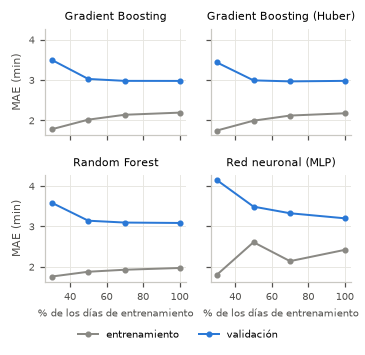

MAE_train                      MAE_val         \
fraccion                        0.3    0.5    0.7    1.0     0.3    0.5   
modelo                                                                    
Gradient Boosting             1.783  2.020  2.142  2.194   3.501  3.029   
Gradient Boosting (Huber)     1.752  1.995  2.122  2.178   3.437  2.994   
Random Forest                 1.760  1.878  1.928  1.972   3.588  3.143   
Red neuronal (MLP)            1.806  2.610  2.141  2.420   4.146  3.492   

                                         
fraccion                     0.7    1.0  
modelo                                   
Gradient Boosting          2.981  2.980  
Gradient Boosting (Huber)  2.968  2.981  
Random Forest              3.097  3.087  
Red neuronal (MLP)         3.328  3.202

In [8]:
# Curvas de aprendizaje en k = 9: MAE de entrenamiento y de validación según la cantidad de días de entrenamiento.
tr9, _ = particion(datos[9])
cols9 = columnas_modelo(datos[9])
cv9 = pliegues(tr9["bloque"])
alpha9 = float(huber.query("k == 9 and modelo == 'GB Huber'")["parametro"].item().split("= ")[1])
candidatos = {
    "Gradient Boosting": clone(REGRESORES["Gradient Boosting"][0]).set_params(**parametros(hiper_reg, 9, "Gradient Boosting")),
    "Gradient Boosting (Huber)": GradientBoostingRegressor(subsample=0.8, random_state=SEMILLA, loss="huber", alpha=alpha9,
                                                           **parametros(hiper_reg, 9, "Gradient Boosting")),
    "Random Forest": clone(REGRESORES["Random Forest"][0]).set_params(**parametros(hiper_reg, 9, "Random Forest")),
    "Red neuronal (MLP)": clone(mejores_mlp[9].named_steps["modelo"]),
}
# Cada pliegue usa la fracción indicada de SUS días de entrenamiento (los más recientes, junto a la validación);
# así, con el 100 % el error de validación coincide con el de la búsqueda en rejilla. (learning_curve de scikit-learn
# toma como 100 % el tamaño del primer pliegue, el más pequeño, y por eso no se usa.)
fracciones = [0.3, 0.5, 0.7, 1.0]


def punto_curva(nombre, modelo, frac, idx_tr, idx_val):
    usar = idx_tr[-max(1, int(round(frac * len(idx_tr)))):]
    ent, val = tr9.iloc[usar], tr9.iloc[idx_val]
    m = pipeline(cols9, clone(modelo)).fit(ent[cols9], ent["y"])
    return (nombre, frac, float(np.mean(np.abs(m.predict(ent[cols9]) - ent["y"]))),
            float(np.mean(np.abs(m.predict(val[cols9]) - val["y"]))))


puntos = Parallel(n_jobs=-1)(delayed(punto_curva)(n, m, f, a, b) for n, m in candidatos.items()
                             for f in fracciones for a, b in cv9)
curvas = (pd.DataFrame(puntos, columns=["modelo", "fraccion", "MAE_train", "MAE_val"])
          .groupby(["modelo", "fraccion"], sort=False).mean().reset_index())
curvas.to_csv(DIR_TAB / "07_curvas_aprendizaje_k9.csv", index=False, float_format="%.4f")

fig, ejes = plt.subplots(2, 2, figsize=(3.5, 3.1), sharex=True, sharey=True)
for ax, (nombre, d) in zip(ejes.ravel(), curvas.groupby("modelo", sort=False)):
    ax.plot(d["fraccion"] * 100, d["MAE_train"], marker="o", markersize=3, linewidth=1.3, color=graficos.GRIS, label="entrenamiento")
    ax.plot(d["fraccion"] * 100, d["MAE_val"], marker="o", markersize=3, linewidth=1.3, color=graficos.PALETA[0], label="validación")
    ax.set_title(nombre, fontsize=7)
    ax.tick_params(labelsize=6.5)
for ax in ejes[1]:
    ax.set_xlabel("% de los días de entrenamiento", fontsize=6.5)
for ax in ejes[:, 0]:
    ax.set_ylabel("MAE (min)", fontsize=7)
manejadores, etiquetas = ejes[0, 0].get_legend_handles_labels()
fig.legend(manejadores, etiquetas, fontsize=6.5, ncol=2, loc="lower center", bbox_to_anchor=(0.5, -0.04))
graficos.guardar(fig, DIR_FIG / "07_curvas_aprendizaje_k9.png")
curvas.pivot(index="modelo", columns="fraccion", values=["MAE_train", "MAE_val"]).round(3)

In [9]:
# Gradient Boosting: error de entrenamiento y de validación según el número de árboles (k = 9, pliegue final).
ent, val = tr9[tr9["bloque"] < 3], tr9[tr9["bloque"] == 3]
filas_it = []
for nombre in ("Gradient Boosting", "Gradient Boosting (Huber)"):
    m = pipeline(cols9, clone(candidatos[nombre])).fit(ent[cols9], ent["y"])
    pre, gb = m[:-1], m.named_steps["modelo"]
    X_ent, X_val = pre.transform(ent[cols9]), pre.transform(val[cols9])
    for i, (p_ent, p_val) in enumerate(zip(gb.staged_predict(X_ent), gb.staged_predict(X_val)), start=1):
        if i % 50 == 0 or i == gb.n_estimators_:
            filas_it.append({"modelo": nombre, "arboles": i, "MAE_train": np.mean(np.abs(p_ent - ent["y"])),
                             "MAE_val": np.mean(np.abs(p_val - val["y"]))})
iteraciones = pd.DataFrame(filas_it)
iteraciones.to_csv(DIR_TAB / "07_iteraciones_gb_k9.csv", index=False, float_format="%.4f")
mejor_it = iteraciones.loc[iteraciones.groupby("modelo")["MAE_val"].idxmin()]
print(mejor_it.round(3).to_string(index=False))
iteraciones.groupby("modelo").tail(1).round(3)

                   modelo  arboles  MAE_train  MAE_val
        Gradient Boosting     1000      2.307    3.367
Gradient Boosting (Huber)     1000      2.285    3.439


,modelo,arboles,MAE_train,MAE_val
19,Gradient Boosting,1000,2.307,3.367
39,Gradient Boosting (Huber),1000,2.285,3.439


## 5. Comparación
Diferencia de cada mejora frente a su referencia (negativo = mejor en MAE; positivo = mejor en F1 macro).

In [10]:
def diferencia(tabla, valor, candidato, referencia, indice="modelo"):
    t = tabla.pivot_table(index=indice, columns="k", values=valor, sort=False)
    return (t.loc[candidato] - t.loc[referencia]).rename(f"{candidato} − {referencia} ({valor})")


resumen = pd.DataFrame([
    diferencia(huber, "MAE_val", "GB Huber", "GB cuadrática (notebook 04)"),
    diferencia(huber, "MAE", "GB Huber", "GB cuadrática (notebook 04)"),
    diferencia(mlp, "MAE_val", "MLP", "Gradient Boosting (notebook 04)"),
    diferencia(mlp, "MAE", "MLP", "Gradient Boosting (notebook 04)"),
])
for nombre in ("Gradient Boosting", "AdaBoost"):
    p = pesos[pesos["modelo"] == nombre]
    resumen.loc[f"{nombre}: balanceados − sin pesos (F1_macro_val)"] = diferencia(p, "F1_macro_val", "balanceados", "sin pesos (notebook 05)", "pesos")
    resumen.loc[f"{nombre}: balanceados − sin pesos (F1_macro)"] = diferencia(p, "F1_macro", "balanceados", "sin pesos (notebook 05)", "pesos")
resumen.to_csv(DIR_TAB / "07_resumen_mejoras.csv", float_format="%.4f")
resumen.round(3)

k,4,6,9,12,15
GB Huber − GB cuadrática (notebook 04) (MAE_val),-0.034,-0.033,0.001,-0.054,-0.037
GB Huber − GB cuadrática (notebook 04) (MAE),-0.039,-0.074,-0.049,-0.069,-0.046
MLP − Gradient Boosting (notebook 04) (MAE_val),0.177,0.201,0.223,0.140,0.077
MLP − Gradient Boosting (notebook 04) (MAE),0.442,0.279,0.455,0.293,0.078
Gradient Boosting: balanceados − sin pesos (F1_macro_val),-0.032,-0.028,-0.029,-0.029,-0.042
Gradient Boosting: balanceados − sin pesos (F1_macro),-0.028,-0.051,-0.039,-0.031,-0.030
AdaBoost: balanceados − sin pesos (F1_macro_val),-0.045,-0.039,-0.021,-0.027,-0.032
AdaBoost: balanceados − sin pesos (F1_macro),-0.030,-0.038,-0.041,-0.028,-0.040


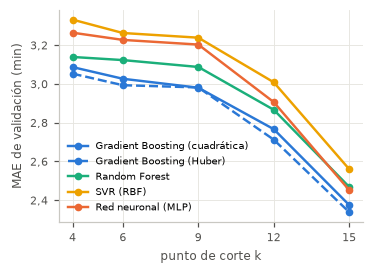

In [11]:
# Figura: MAE de validación por k de los regresores comparados (Huber y MLP frente a los mejores del notebook 04).
comp = pd.concat([huber, mlp[mlp["modelo"] != "Gradient Boosting (notebook 04)"]])
comp["modelo"] = comp["modelo"].replace({"GB cuadrática (notebook 04)": "Gradient Boosting (cuadrática)",
                                         "GB Huber": "Gradient Boosting (Huber)",
                                         "Random Forest (notebook 04)": "Random Forest",
                                         "SVR (RBF) (notebook 04)": "SVR (RBF)", "MLP": "Red neuronal (MLP)"})
estilo = {"Gradient Boosting (cuadrática)": (graficos.PALETA[0], "-"), "Gradient Boosting (Huber)": (graficos.PALETA[0], "--"),
          "Random Forest": (graficos.PALETA[2], "-"), "SVR (RBF)": (graficos.PALETA[3], "-"),
          "Red neuronal (MLP)": (graficos.PALETA[1], "-")}
fig, ax = plt.subplots(figsize=(3.5, 2.6))
for nombre, (color, linea) in estilo.items():
    d = comp[comp["modelo"] == nombre].sort_values("k")
    ax.plot(d["k"], d["MAE_val"], linestyle=linea, marker="o", color=color, label=nombre, linewidth=1.6, markersize=4)
ax.set(xticks=list(CORTES), xlabel="punto de corte k", ylabel="MAE de validación (min)")
ax.tick_params(labelsize=7.5)
ax.xaxis.label.set_size(8)
ax.yaxis.label.set_size(8)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1f}".replace(".", ",")))
ax.legend(fontsize=6.5, loc="lower left")
graficos.guardar(fig, DIR_FIG / "07_mejoras_regresion.png")

## 6. Modelo de la demo: Gradient Boosting con pérdida de Huber frente a la meta del 80 %
La demo usa el mejor modelo de las pruebas: Gradient Boosting con pérdida de Huber y los hiperparámetros del notebook 04 en los cinco cortes. Se valida en la semana de prueba con las métricas en escala 0–1: R², proporción de vueltas con error de 5 min o menos y, al convertir la predicción en estados con los umbrales de 5 y 3 min, exactitud, F1 macro, AUC-PR de atrasado y matriz de confusión.

In [12]:
from sklearn.metrics import confusion_matrix

CLASES = ["adelantado", "a tiempo", "atrasado"]
filas_demo, matrices_demo = [], {}
for k in CORTES:
    tr, te = particion(datos[k])
    cols = columnas_modelo(datos[k])
    alpha = float(huber.query("k == @k and modelo == 'GB Huber'")["parametro"].item().split("= ")[1])
    m = pipeline(cols, GradientBoostingRegressor(subsample=0.8, random_state=SEMILLA, loss="huber", alpha=alpha,
                                                 **parametros(hiper_reg, k, "Gradient Boosting"))).fit(tr[cols], tr["y"])
    pred = m.predict(te[cols])
    reg = metricas_regresion(te["y"], pred)
    clf = metricas_clasificacion(a_clase(te["y"]), a_clase(pred), pred)
    matrices_demo[k] = confusion_matrix(a_clase(te["y"]), a_clase(pred), labels=CLASES)
    filas_demo.append({"k": k, "MAE": reg["MAE"], "R2": reg["R2"], "error_5min": reg["pct_err_5"] / 100,
                       "exactitud": clf["exactitud"], "F1_macro": clf["F1_macro"],
                       "AUC_PR_atrasado": clf["AUC_PR_atrasado"]})
demo = pd.DataFrame(filas_demo).set_index("k")
demo.to_csv(DIR_TAB / "07_modelo_demo_meta80.csv", float_format="%.4f")
pd.DataFrame(matrices_demo[9], index=CLASES, columns=CLASES).to_csv(DIR_TAB / "07_modelo_demo_confusion_k9.csv")
print("Métricas que superan 0,80 por corte:")
print((demo.drop(columns="MAE") >= 0.80).replace({True: "sí", False: "no"}).T.to_string())
demo.round(3)

Métricas que superan 0,80 por corte:
k                4   6   9   12  15
R2               no  no  no  no  sí
error_5min       sí  sí  sí  sí  sí
exactitud        no  sí  sí  sí  sí
F1_macro         no  no  no  no  no
AUC_PR_atrasado  sí  sí  sí  sí  sí


,MAE,R2,error_5min,exactitud,F1_macro,AUC_PR_atrasado
k,,,,,,
4,2.619,0.742,0.876,0.795,0.751,0.825
6,2.591,0.747,0.877,0.802,0.764,0.825
9,2.576,0.758,0.876,0.800,0.768,0.817
12,2.395,0.796,0.896,0.812,0.779,0.851
15,2.003,0.849,0.943,0.838,0.797,0.886


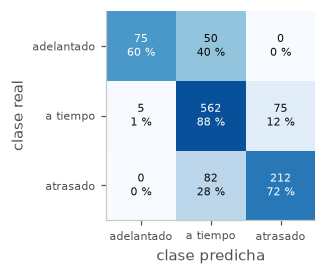

In [13]:
# Matriz de confusión del modelo de la demo en k = 9 (número de vueltas y % de cada clase real)
mc = matrices_demo[9]
porc = mc / mc.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(3.0, 2.6))
ax.imshow(porc, cmap="Blues", vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{mc[i, j]}\n{100 * porc[i, j]:.0f} %", ha="center", va="center", fontsize=7.5,
                color="white" if porc[i, j] > 0.5 else graficos.TEXTO)
ax.set(xticks=range(3), yticks=range(3), xticklabels=CLASES, yticklabels=CLASES, xlabel="clase predicha",
       ylabel="clase real")
ax.tick_params(labelsize=7)
ax.grid(False)
graficos.guardar(fig, DIR_FIG / "07_modelo_demo_confusion_k9.png")

## 7. Conclusiones
- **Pérdida de Huber (Gradient Boosting):** con los hiperparámetros del notebook 04, baja el MAE de validación en 4 de los 5 cortes (−0,03 a −0,05 min; en k = 9 queda igual, +0,002) y el de prueba en los 5 (−0,04 a −0,07 min; en k = 9, de 2,62 a 2,58 min, R² 0,758). Mejora pequeña pero consistente, coherente con H5. Se usa en la demo y se reporta en el paper sin reemplazar las cifras principales.
- **Red neuronal (MLP) con búsqueda equivalente:** con las mismas 81 combinaciones que Gradient Boosting, los mismos pliegues y variables y una capacidad del mismo orden (5.377 a 61.953 parámetros frente a 2.279 a 11.929 hojas), queda entre 0,08 y 0,22 min por encima de Gradient Boosting en validación (k = 9: 3,20 frente a 2,98) y por debajo de Random Forest. Con unas 3.000 vueltas tabulares, los ensambles de árboles siguen siendo la mejor opción.
- **Pesos balanceados (clasificación):** suben la exactitud balanceada pero bajan el F1 macro de validación entre 0,02 y 0,05 en Gradient Boosting y AdaBoost. No se adoptan.
- **Diagnóstico de ajuste:** Gradient Boosting tiene una brecha moderada entre entrenamiento y validación (2,39 y 2,98 min en k = 9) y la mejor validación y prueba; Random Forest, Bagging y KNN sobreajustan más y los modelos lineales subajustan (≈ 3,2 min incluso en entrenamiento). En clasificación, la brecha de F1 macro es 0,05 en Gradient Boosting y 0,02 en AdaBoost, frente a 0,18 en Random Forest y 0,28 en KNN. Las curvas de aprendizaje convergen (validación de 3,50 a 2,98 min, estable desde el 70 % de los días) y agregar árboles no empeora la validación: no hay sobreajuste en el modelo elegido.
- **Modelo de la demo frente a la meta del 80 %:** en prueba supera 0,80 en el porcentaje de vueltas con error de 5 min o menos (0,876 a 0,942) y en el AUC-PR de atrasado (0,817 a 0,886) en los cinco cortes, y en la exactitud al convertir la predicción en estados desde k = 6 (0,800 en k = 9; 0,796 en k = 4). El R² la supera solo en k = 15 y el F1 macro queda entre 0,75 y 0,80.
- Este notebook no cambia las tablas de los notebooks 04 a 06; sus resultados están en `results/tables/07_*.csv` y `results/figures/07_*.png`.

In [14]:
import platform, sklearn, scipy, matplotlib
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__)

Python 3.14.2 | pandas 3.0.3 | numpy 2.5.0 | scikit-learn 1.9.0 | scipy 1.18.0 | matplotlib 3.11.0
